# TA-04: Peramalan Kecepatan Angin per Jam Menggunakan LSTM pada Data SCADA Turbin Angin
**Mata Praktikum:** Pembelajaran Mesin | **Modul 04 - LSTM**

**Dataset:** Wind Turbine SCADA Dataset (Kaggle, `berkerisen/wind-turbine-scada-dataset`), interval 10 menit.

**Tujuan:** meramalkan **kecepatan angin (m/s) satu jam ke depan** berdasarkan data 24 jam terakhir (kecepatan dan arah angin).

**Alur:** 1) Muat data -> 2) EDA -> 3) Pembersihan & resampling per jam -> 4) Split kronologis -> 5) Scaling -> 6) Windowing & reshape 3D -> 7) Model LSTM -> 8) Evaluasi -> 9) Simpan model & scaler

In [1]:
import os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED); np.random.seed(SEED)
import tensorflow as tf
tf.random.set_seed(SEED)

# ====== PENGATURAN (silakan diubah untuk eksperimen) ======
CSV_PATH   = "T1.csv"
TIMESTEPS  = 24        # pakai 24 jam terakhir untuk memprediksi jam berikutnya
EPOCHS     = 50
BATCH_SIZE = 64
TRAIN_RATIO = 0.8
os.makedirs("artifacts", exist_ok=True)

## 1. Memuat Data

In [2]:
df = pd.read_csv(CSV_PATH)
df.columns = ["datetime", "power_kw", "wind_speed", "theoretical_power", "wind_dir"]

try:
    df["datetime"] = pd.to_datetime(df["datetime"], format="%d %m %Y %H:%M")
except ValueError:
    df["datetime"] = pd.to_datetime(df["datetime"], dayfirst=True)

df = df.set_index("datetime").sort_index()
print(df.shape)
df.head()

(50530, 4)


,power_kw,wind_speed,theoretical_power,wind_dir
datetime,,,,
2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904
2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113
2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789
2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087
2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286


## 2. Eksplorasi Data (EDA)

In [3]:
display(df.describe().T)
print("Nilai kosong per kolom:\n", df.isna().sum())
print("Timestamp duplikat:", df.index.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
power_kw,50530.0,1307.684332,1312.459242,-2.471405,50.677890,825.838074,2482.507568,3618.732910
wind_speed,50530.0,7.557952,4.227166,0.000000,4.201395,7.104594,10.300020,25.206011
theoretical_power,50530.0,1492.175463,1368.018238,0.000000,161.328167,1063.776283,2964.972462,3600.000000
wind_dir,50530.0,123.687559,93.443736,0.000000,49.315437,73.712978,201.696720,359.997589


Nilai kosong per kolom:
 power_kw             0
wind_speed           0
theoretical_power    0
wind_dir             0
dtype: int64
Timestamp duplikat: 0


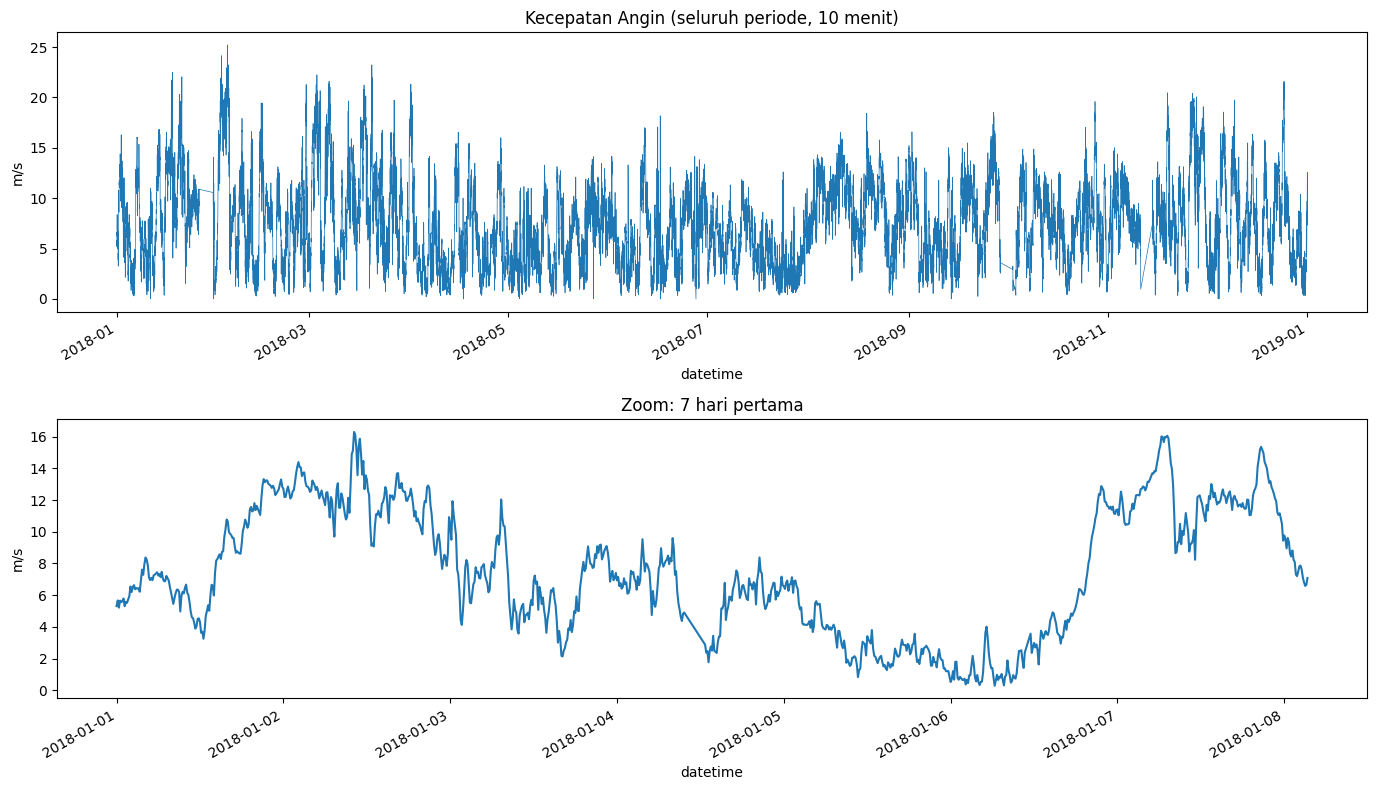

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
df["wind_speed"].plot(ax=axes[0], lw=0.5)
axes[0].set_title("Kecepatan Angin (seluruh periode, 10 menit)"); axes[0].set_ylabel("m/s")
df["wind_speed"].iloc[:6*24*7].plot(ax=axes[1])
axes[1].set_title("Zoom: 7 hari pertama"); axes[1].set_ylabel("m/s")
plt.tight_layout(); plt.show()

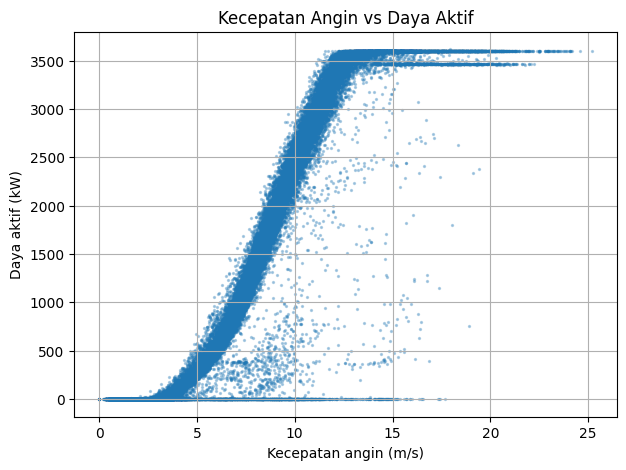

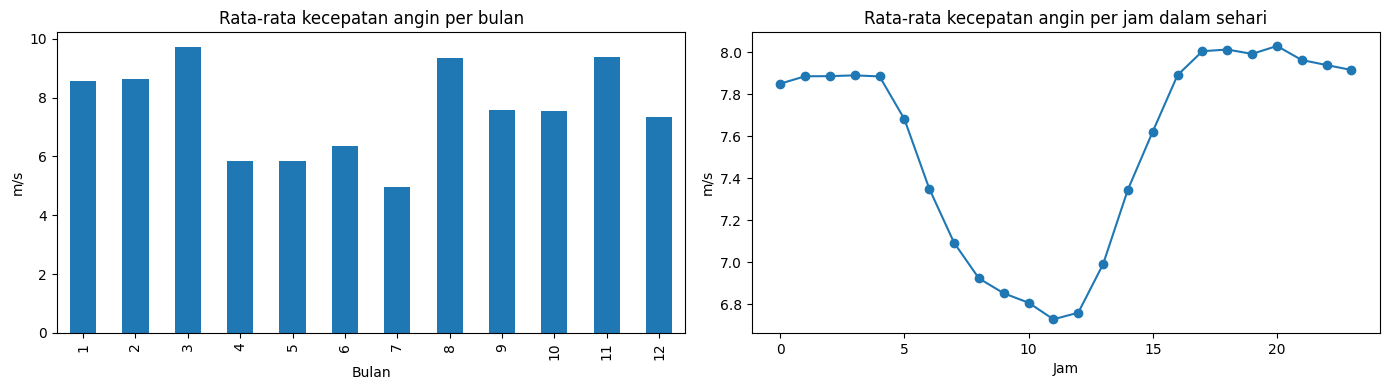

In [5]:
# Hubungan kecepatan angin dengan daya turbin (konteks: kurva daya)
plt.figure(figsize=(7, 5))
plt.scatter(df["wind_speed"], df["power_kw"], s=2, alpha=0.3)
plt.xlabel("Kecepatan angin (m/s)"); plt.ylabel("Daya aktif (kW)")
plt.title("Kecepatan Angin vs Daya Aktif"); plt.grid(True); plt.show()

# Pola musiman: rata-rata per bulan & per jam dalam sehari
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["wind_speed"].groupby(df.index.month).mean().plot(kind="bar", ax=axes[0])
axes[0].set_title("Rata-rata kecepatan angin per bulan"); axes[0].set_xlabel("Bulan"); axes[0].set_ylabel("m/s")
df["wind_speed"].groupby(df.index.hour).mean().plot(ax=axes[1], marker="o")
axes[1].set_title("Rata-rata kecepatan angin per jam dalam sehari"); axes[1].set_xlabel("Jam"); axes[1].set_ylabel("m/s")
plt.tight_layout(); plt.show()

**Catatan EDA (isi dengan temuanmu sendiri setelah melihat plot):** tren, musiman bulanan/harian, perbedaan kecepatan angin antar bulan dan antar jam dalam sehari, hubungan kecepatan angin dengan daya, serta nilai ekstrem.

## 3. Pembersihan & Resampling per Jam
Data 10 menit sangat rapat sehingga menebak 10 menit ke depan hampir trivial. Kita agregasi ke rata-rata **per jam** agar masalahnya lebih bermakna dan pelatihan lebih cepat.

In [6]:
# arah angin bersifat melingkar (0-360 derajat), jadi diubah ke komponen sin/cos sebelum dirata-ratakan
df["dir_sin"] = np.sin(np.deg2rad(df["wind_dir"]))
df["dir_cos"] = np.cos(np.deg2rad(df["wind_dir"]))

hourly = df[["wind_speed", "dir_sin", "dir_cos"]].resample("1h").mean()
print("Jam tanpa data (gap):", hourly["wind_speed"].isna().sum())

# isi gap dengan interpolasi berbasis waktu
hourly = hourly.interpolate(method="time").bfill().ffill()
print(hourly.shape)
hourly.head()

Jam tanpa data (gap): 321
(8760, 3)


,wind_speed,dir_sin,dir_cos
datetime,,,
2018-01-01 00:00:00,5.506868,-0.995991,-0.050109
2018-01-01 01:00:00,5.644205,-0.977053,-0.190904
2018-01-01 02:00:00,6.452037,-0.998210,-0.027952
2018-01-01 03:00:00,6.811455,-0.968756,-0.241261
2018-01-01 04:00:00,7.748749,-0.920376,-0.378368


## 4. Split Kronologis (80% latih, 20% uji)
**Penting:** data time series **tidak boleh diacak**. Data uji harus berada setelah data latih.

In [7]:
FEATURES = ["wind_speed", "dir_sin", "dir_cos"]   # fitur input
TARGET   = "wind_speed"                          # variabel yang diprediksi

split_idx = int(len(hourly) * TRAIN_RATIO)
print("Data latih :", hourly.index[0], "->", hourly.index[split_idx - 1])
print("Data uji   :", hourly.index[split_idx], "->", hourly.index[-1])

Data latih : 2018-01-01 00:00:00 -> 2018-10-19 23:00:00
Data uji   : 2018-10-20 00:00:00 -> 2018-12-31 23:00:00


## 5. Scaling (MinMaxScaler)
Scaler **hanya di-fit pada data latih** agar tidak ada kebocoran informasi dari data uji.

In [8]:
scaler_X = MinMaxScaler(feature_range=(0, 1))
scaler_y = MinMaxScaler(feature_range=(0, 1))

scaler_X.fit(hourly[FEATURES].iloc[:split_idx])
scaler_y.fit(hourly[[TARGET]].iloc[:split_idx])

scaled_X = scaler_X.transform(hourly[FEATURES])
scaled_y = scaler_y.transform(hourly[[TARGET]]).ravel()

## 6. Windowing & Reshape 3D
Setiap sampel: `TIMESTEPS` jam terakhir -> daya pada jam berikutnya.
Bentuk input LSTM: `(samples, timesteps, features)`.

In [9]:
X, y, target_pos = [], [], []
for i in range(TIMESTEPS, len(scaled_X)):
    X.append(scaled_X[i - TIMESTEPS:i, :])
    y.append(scaled_y[i])
    target_pos.append(i)

X = np.array(X); y = np.array(y); target_pos = np.array(target_pos)
print("X:", X.shape, "(samples, timesteps, features)")
print("y:", y.shape)

# sampel dengan jam target di data latih -> latih; sisanya -> uji
train_mask = target_pos < split_idx
X_train, y_train = X[train_mask],  y[train_mask]
X_test,  y_test  = X[~train_mask], y[~train_mask]
test_pos = target_pos[~train_mask]
print("Latih:", X_train.shape, "| Uji:", X_test.shape)

X: (8736, 24, 3) (samples, timesteps, features)
y: (8736,)
Latih: (6984, 24, 3) | Uji: (1752, 24, 3)


## 7. Membangun & Melatih Model LSTM

In [10]:
n_features = X.shape[2]
model = Sequential([
    Input(shape=(TIMESTEPS, n_features)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1),
])
model.compile(optimizer="adam", loss="mean_squared_error")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,369 (118.63 KB)

 Trainable params: 30,369 (118.63 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stop = EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,      # 10% data latih paling akhir dipakai sebagai validasi
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - loss: 0.0228 - val_loss: 0.0072
Epoch 2/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - loss: 0.0107 - val_loss: 0.0056
Epoch 3/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0084 - val_loss: 0.0053
Epoch 4/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0071 - val_loss: 0.0039
Epoch 5/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.0063 - val_loss: 0.0035
Epoch 6/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - loss: 0.0056 - val_loss: 0.0031
Epoch 7/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - loss: 0.0051 - val_loss: 0.0026
Epoch 8/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - loss: 0.0046 - val_loss: 0.0023
Epoch 9/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - loss: 0.0043 - val_loss: 0.0021
Epoch 10/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 11s 105ms/step - loss: 0.0042 - val_loss: 0.0021
Epoch 11/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 10s 98ms/step - loss: 0.0039 - val_loss: 0.0021
Epoch 12/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - loss:

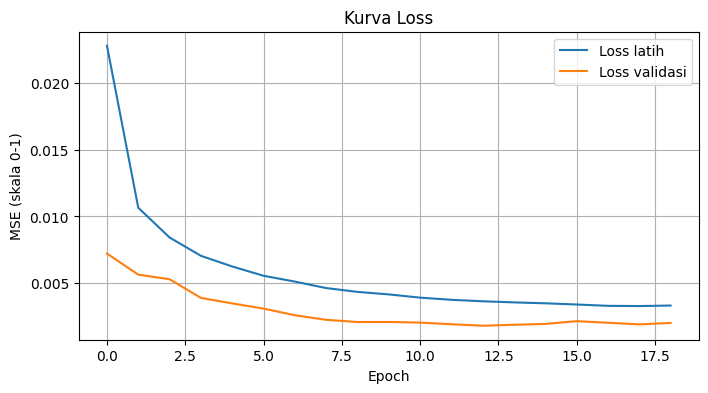

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Loss latih")
plt.plot(history.history["val_loss"], label="Loss validasi")
plt.xlabel("Epoch"); plt.ylabel("MSE (skala 0-1)"); plt.title("Kurva Loss")
plt.legend(); plt.grid(True); plt.show()

## 8. Evaluasi Model

In [13]:
pred_scaled = model.predict(X_test)
pred = scaler_y.inverse_transform(pred_scaled).ravel()
actual = scaler_y.inverse_transform(y_test.reshape(-1, 1)).ravel()

# kecepatan angin tidak mungkin negatif / melebihi nilai maksimum yang pernah teramati
pred = np.clip(pred, 0, hourly[TARGET].max())

rmse = np.sqrt(mean_squared_error(actual, pred))
mae  = mean_absolute_error(actual, pred)

# Baseline sederhana: "persistence" (kecepatan angin jam ini = jam sebelumnya)
baseline = hourly[TARGET].values[test_pos - 1]
rmse_base = np.sqrt(mean_squared_error(actual, baseline))
mae_base  = mean_absolute_error(actual, baseline)

print(f"LSTM        -> RMSE: {rmse:8.3f} m/s | MAE: {mae:8.3f} m/s")
print(f"Persistence -> RMSE: {rmse_base:8.3f} m/s | MAE: {mae_base:8.3f} m/s")
print(f"Nilai maksimum teramati: {hourly[TARGET].max():.2f} m/s")

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
LSTM        -> RMSE:    1.186 m/s | MAE:    0.869 m/s
Persistence -> RMSE:    1.154 m/s | MAE:    0.811 m/s
Nilai maksimum teramati: 23.75 m/s


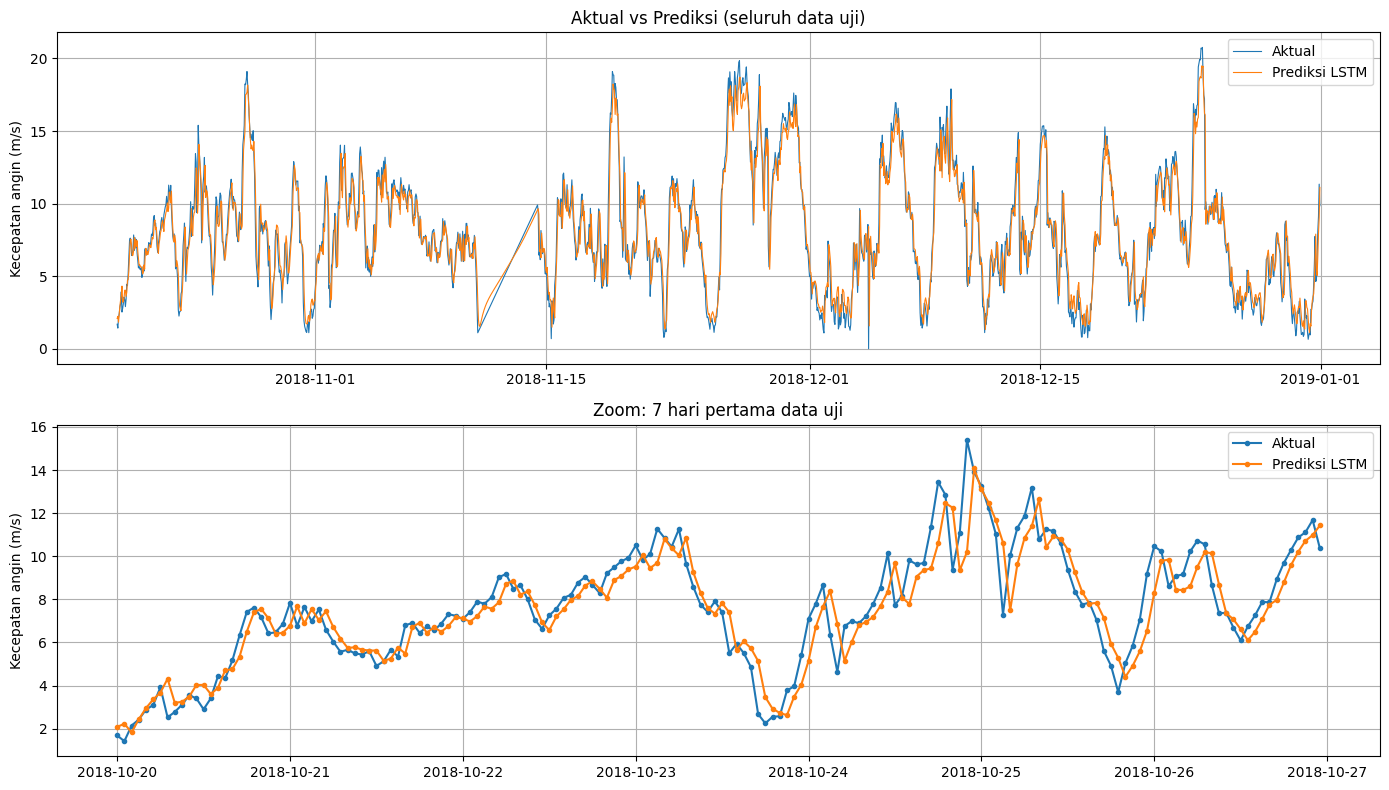

In [14]:
test_index = hourly.index[test_pos]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].plot(test_index, actual, label="Aktual", lw=0.8)
axes[0].plot(test_index, pred, label="Prediksi LSTM", lw=0.8)
axes[0].set_title("Aktual vs Prediksi (seluruh data uji)"); axes[0].legend(); axes[0].grid(True)

n = 24 * 7
axes[1].plot(test_index[:n], actual[:n], label="Aktual", marker="o", ms=3)
axes[1].plot(test_index[:n], pred[:n], label="Prediksi LSTM", marker="o", ms=3)
axes[1].set_title("Zoom: 7 hari pertama data uji"); axes[1].legend(); axes[1].grid(True)
for ax in axes: ax.set_ylabel("Kecepatan angin (m/s)")
plt.tight_layout(); plt.show()

**Interpretasi (lengkapi dengan analisismu):** bandingkan RMSE/MAE LSTM dengan baseline persistence. Jika LSTM belum mengalahkan baseline, coba tambah fitur, ubah `TIMESTEPS`, atau ubah ukuran layer. Jelaskan juga di bagian mana model sering meleset (misalnya saat kecepatan angin berubah tajam).

## 9. Menyimpan Model, Scaler, dan Data untuk Aplikasi Flask

In [15]:
model.save("artifacts/model_lstm.keras")
model.save("artifacts/model_lstm.h5")            # format .h5 sesuai ketentuan modul
joblib.dump(scaler_X, "artifacts/scaler_X.joblib")
joblib.dump(scaler_y, "artifacts/scaler_y.joblib")

config = {
    "timesteps": TIMESTEPS,
    "features": FEATURES,
    "target": TARGET,
    "freq": "1h",
    "max_value": float(hourly[TARGET].max()),
    "unit": "m/s",
    "rmse": float(rmse), "mae": float(mae),
    "rmse_baseline": float(rmse_base), "mae_baseline": float(mae_base),
}
with open("artifacts/config.json", "w") as f:
    json.dump(config, f, indent=2)

hourly.reset_index().rename(columns={"datetime": "datetime"}).to_csv("artifacts/hourly_data.csv", index=False)
pd.DataFrame({"datetime": test_index, "actual": actual, "prediction": pred}).to_csv("artifacts/test_predictions.csv", index=False)
print(os.listdir("artifacts"))

['config.json', 'hourly_data.csv', 'model_lstm.h5', 'model_lstm.keras', 'README.txt', 'scaler_X.joblib', 'scaler_y.joblib', 'test_predictions.csv']
